In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_regression


In [4]:
employee=pd.read_csv('HR-Employee-Attrition.csv')

In [5]:
employee.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## data cleaning and analys

In [4]:
employee.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [5]:
employee.shape

(1470, 35)

In [6]:
employee.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [7]:
employee.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [8]:
employee.duplicated().sum()

np.int64(0)

In [9]:
employee.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [10]:
employee.loc[employee['Age'] > 30, ['MonthlyIncome']]

,MonthlyIncome
0,5993
1,5130
2,2090
3,2909
5,3068
...,...
1463,9936
1465,2571
1466,9991
1468,5390


## encoding the catogorical data

In [11]:
encode=LabelEncoder()

In [12]:
employee['Department']=encode.fit_transform(employee['Department'])
employee['EducationField']=encode.fit_transform(employee['EducationField'])

## feature selection for modeling

In [16]:
emp_select=list(employee.select_dtypes(include='int64'))
emp_select.remove( 'MonthlyIncome')

In [17]:
type(emp_select)

list

In [18]:
corr = employee[emp_select + ['MonthlyIncome']].corr()['MonthlyIncome'].sort_values(ascending=False)
correlation=corr[1:].head(10)
correlation

JobLevel                   0.950300
TotalWorkingYears          0.772893
YearsAtCompany             0.514285
Age                        0.497855
YearsInCurrentRole         0.363818
YearsSinceLastPromotion    0.344978
YearsWithCurrManager       0.344079
NumCompaniesWorked         0.149515
Education                  0.094961
Department                 0.053130
Name: MonthlyIncome, dtype: float64

In [19]:
feature=['JobLevel','TotalWorkingYears','YearsAtCompany','Age','YearsInCurrentRole','YearsSinceLastPromotion','NumCompaniesWorked','Education','Department']
x=employee[feature]
y=employee['MonthlyIncome']

## select the best feature

In [20]:
selector=SelectKBest(score_func=f_regression,k=5)

In [21]:
x_selected=selector.fit_transform(x,y)

In [22]:
x_selected

array([[ 2,  8,  6, 41,  4],
       [ 2, 10, 10, 49,  7],
       [ 1,  7,  0, 37,  0],
       ...,
       [ 2,  6,  6, 27,  2],
       [ 2, 17,  9, 49,  6],
       [ 2,  6,  4, 34,  3]], shape=(1470, 5))

In [23]:
x_select_best=x.columns[selector.get_support()]

In [24]:
x=employee[x_select_best]
y=employee['MonthlyIncome']

## scaling

In [25]:
scale=StandardScaler()
x_scaled=scale.fit_transform(x)


## split the train and test data

In [26]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=43)

## build and train and test the model

In [27]:
model=LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[3746.66, 69.07, 8.73, -9.93, -49.38]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['JobLevel','TotalWorkingYears','YearsAtCompany','Age', 'YearsInCurrentRole']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1484
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [28]:
y_test_pred=model.predict(x_test)
y_train_pred=model.predict(x_train)

## evaluate the model

In [45]:
r2_score_train=r2_score(y_train,y_train_pred)
mean_absolute_train=mean_absolute_error(y_train,y_train_pred)
mean_squared_train=mean_squared_error(y_train,y_train_pred)
rmse_train=np.sqrt(mean_squared_train)


In [42]:
r2_score_train


0.9049179270147014

In [43]:
mean_absolute_train

1091.988431179955

In [40]:
mean_squared_train

2040868.835810029

In [46]:
rmse_train

np.float64(1428.58980670101)

In [47]:
r2_score_test=r2_score(y_test,y_test_pred)
mean_absolute_test=mean_absolute_error(y_test,y_test_pred)
mean_squared_test=mean_squared_error(y_test,y_test_pred)
rmse_test=np.sqrt(mean_squared_test)

In [48]:
r2_score_test

0.9072934599286262

In [49]:
mean_absolute_test

1118.8381181651205

In [50]:
mean_squared_test

2195078.7465190915

In [51]:
rmse_test

np.float64(1481.5798144275223)

## check the overfitting

In [54]:
overfit=abs(r2_score_train-r2_score_test)
overfit

0.0023755329139247827

In [55]:
if overfit<0.5:
    print("our model is not a overfit")
else:
    print("our model is overfit")

our model is not a overfit


## visualize the model 

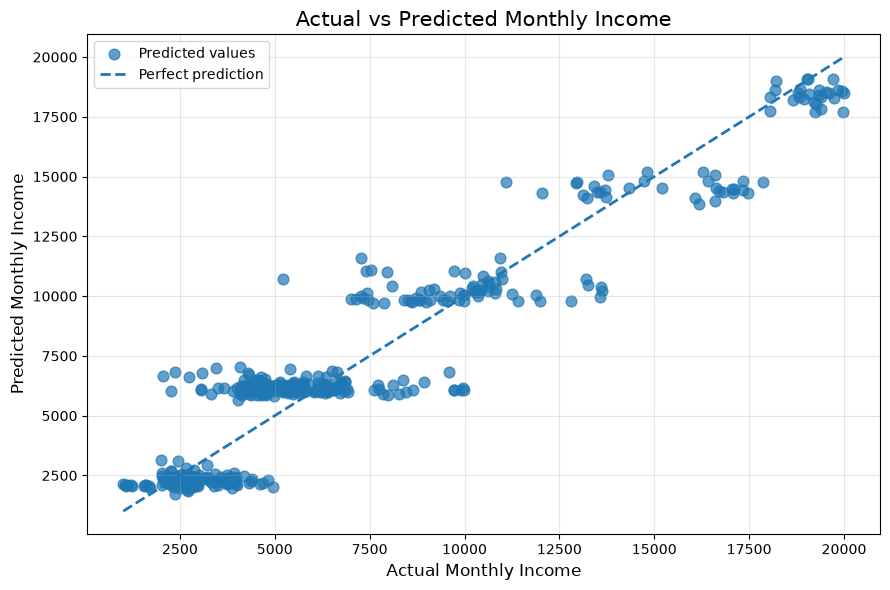

In [75]:
plt.figure(figsize=(9,6))

# Actual vs Predicted points
plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.7,
    s=60,
    label="Predicted values"
)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual Monthly Income", fontsize=12)
plt.ylabel("Predicted Monthly Income", fontsize=12)

plt.title(
    "Actual vs Predicted Monthly Income",
    fontsize=15
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

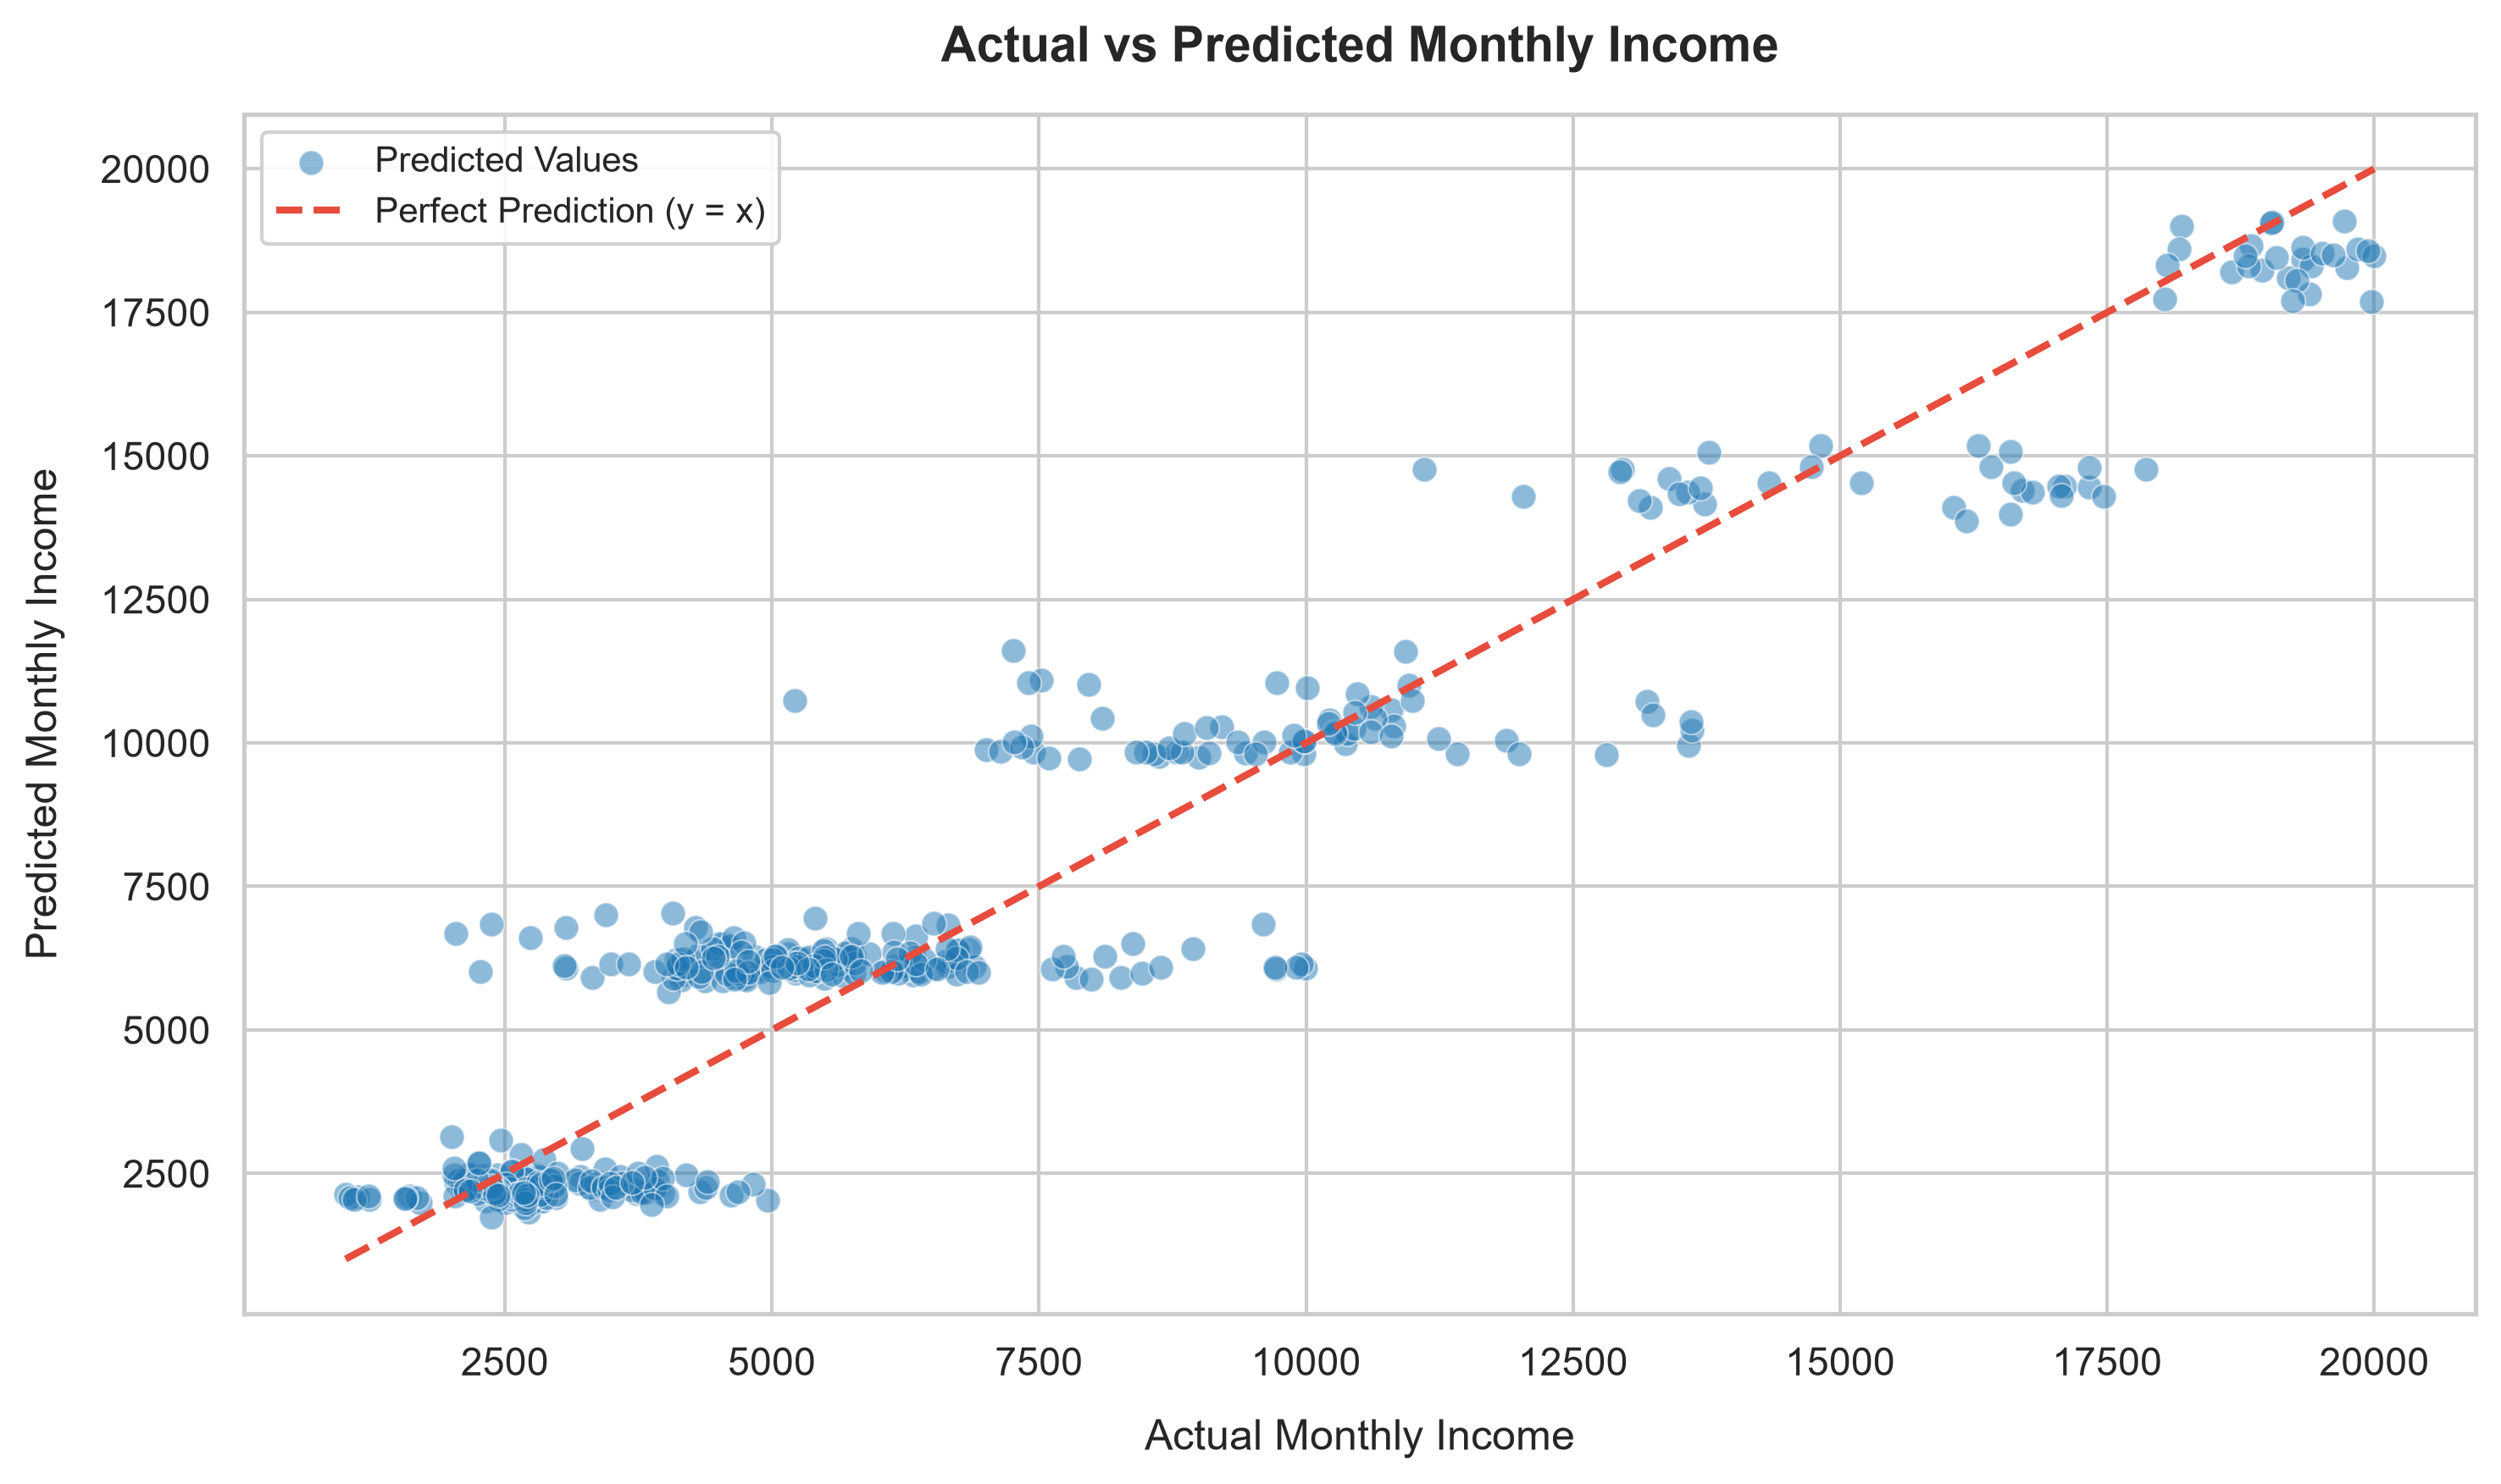

In [81]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6), dpi=300)

# Scatter plot with custom aesthetics
plt.scatter(
    y_test, 
    y_test_pred, 
    color='#1f77b4', 
    alpha=0.5, 
    edgecolor='w', 
    linewidth=0.5, 
    s=50, 
    label='Predicted Values'
)

# Reference / Perfect Prediction Line
min_val = min(min(y_test), min(y_test_pred))
max_val = max(max(y_test), max(y_test_pred))
plt.plot(
        [min_val, max_val], 
        [min_val, max_val], 
        color='#e74c3c', 
        linestyle='--', 
        linewidth=2, 
        label='Perfect Prediction (y = x)'
)

# Labels & Title with proper font sizes
plt.title('Actual vs Predicted Monthly Income', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Actual Monthly Income', fontsize=12, labelpad=10)
plt.ylabel('Predicted Monthly Income', fontsize=12, labelpad=10)

# Legend & Spacing
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.tight_layout()

plt.show()

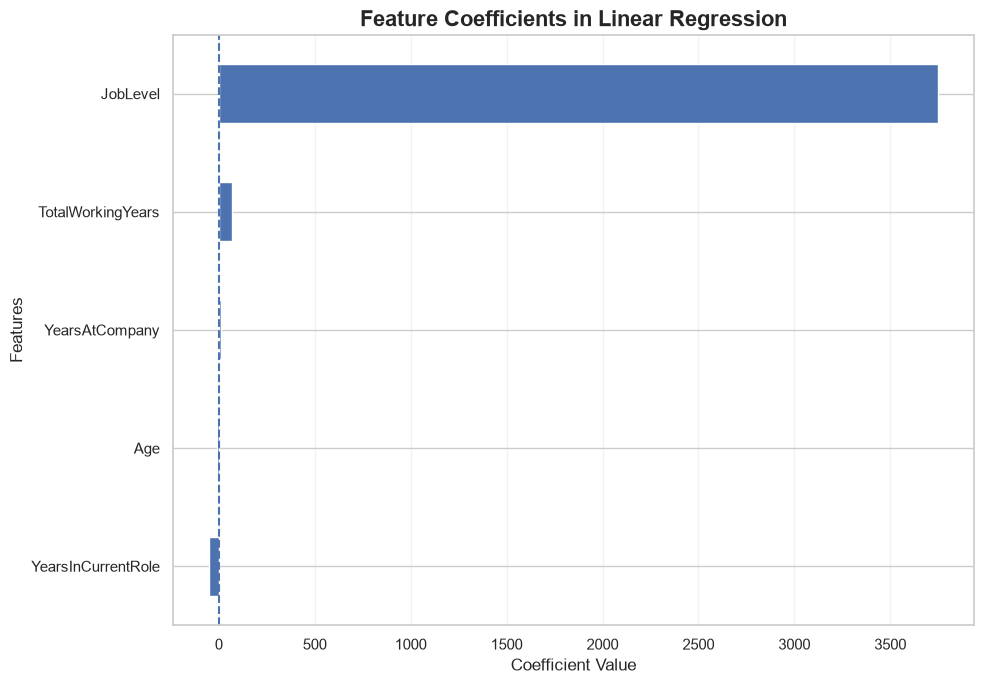

In [83]:
coef = pd.Series(
    model.coef_,
    index=x_train.columns
).sort_values()

plt.figure(figsize=(10, 7))

coef.plot(kind="barh")

plt.axvline(
    0,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Coefficient Value", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.title(
    "Feature Coefficients in Linear Regression",
    fontsize=16,
    fontweight="bold"
)

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

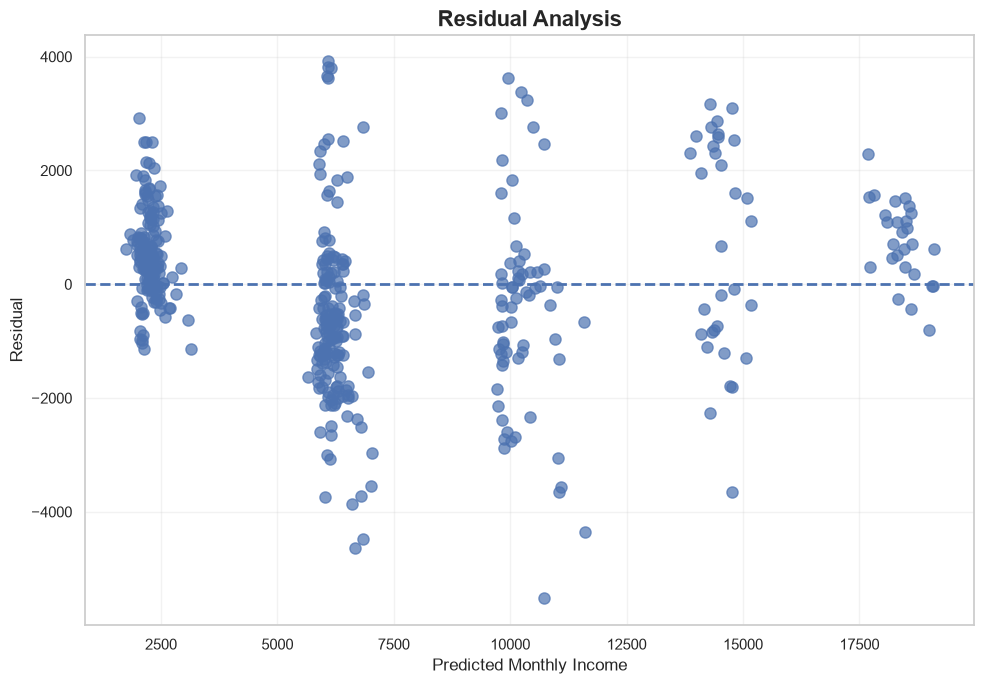

In [84]:
residuals = y_test - y_test_pred

plt.figure(figsize=(10, 7))

plt.scatter(
    y_test_pred,
    residuals,
    s=65,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Monthly Income", fontsize=12)
plt.ylabel("Residual", fontsize=12)

plt.title(
    "Residual Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()